In [1]:
!pip install -q ultralytics roboflow

In [2]:
import cv2
import matplotlib.pyplot as plt

from ultralytics import YOLO
from roboflow import Roboflow
from pathlib import Path

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [3]:
# RoboFlow 프로젝트 접근 준비 -> recycle instance segmentation 검색
rf = Roboflow(api_key="aLiunxQwG6LnaqKvQr9S")
project = rf.workspace("ss-workspace-3c2gu").project("recycle-0mpfl-dt5fs")

# 데이터셋 다운로드
dataset = project.version(1).download('yolov11')

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to recycle-1 in yolov11:: 100%|██████████| 7912/7912 [00:13<00:00, 598.30it/s] 


In [4]:
# seg :: "객체 분할"의 YOLO 모델 불러오기
#    => 객체(물체)의 유무에 넘어서서, 객체(물체)의 영역까지 구분
model = YOLO("yolo11n-seg.pt")

model.train(
    data=dataset.location + "/data.yaml",
    epochs=10,        # 학습 반복 횟수
    imgsz=256         # 학습 이미지 크기
)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/recycle-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=256, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False, opt

ultralytics.utils.metrics.SegmentMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7e9c56ae56d0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)', 'Precision-Recall(M)', 'F1-Confidence(M)', 'Precision-Confidence(M)', 'Recall-Confidence(M)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0

In [5]:
# 성능이 가장 좋았던 모델 가져오기
train_model = YOLO(str(model.trainer.best))

In [13]:
# 데이터셋에 있는 테스트 이미지 가져오기 (.jpg 형식)
test_images = list(
    Path(dataset.location + '/test/images').glob('*.jpg')
)

Image = test_images[10]

# 객체 분할 수행
results = train_model(
    str(Image),
    conf = 0.25
)

rs = results[0]


image 1/1 /content/recycle-1/test/images/17_X002_C203_1103_4_jpg.rf.3dac789e0f21b08bdf4c0203dc2c4940.jpg: 160x256 1 glass, 64.3ms
Speed: 1.2ms preprocess, 64.3ms inference, 9.6ms postprocess per image at shape (1, 3, 160, 256)


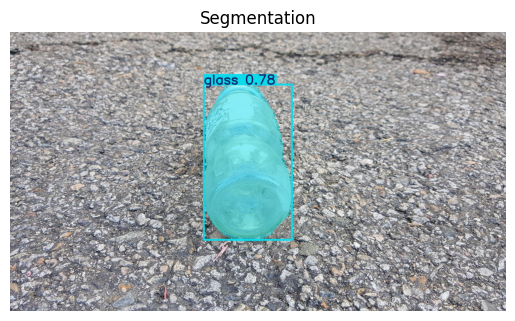

In [14]:
# 객체 분할의 결과를 이미지로 표현
result_img = rs.plot()      # 마스크 탐지

result_img = cv2.cvtColor(result_img, cv2.COLOR_BGR2RGB)

plt.imshow(result_img)
plt.title("Segmentation")
plt.axis("off")

plt.show()

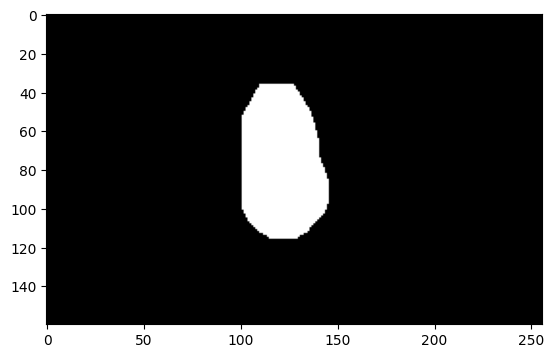

In [15]:
# 마스크 영역을 흰색으로, 아닌 영역을 검정으로 표현

# 마스크 :: 감지된 물체의 영역
if rs.masks is not None:    # "분석 결과에서 마스크가 존재한다면(객체가 확인된다면)"
  # 감지된 마스크 영역 추출 -> numpy 배열로 전환
  #     => 감지된 마스크 영역의 전체에 255값(흰색)으로 전환
  mask = rs.masks.data[0].cpu().numpy()

  plt.imshow(mask, cmap='gray')    # 0은 검정, 255는 흰색
  plt.show()